In [1]:
import mne
import numpy as np
import matplotlib.pyplot as plt

epochs = mne.read_epochs('epochs_vp001_filtradas-epo.fif', preload=True)

canais_selecionados = ['AFz', 'Fp1', 'F1', 'F2', 'Cz', 'Pz', 'O1', 'O2']

# Calcula a média evocada (Evoked) de todas as épocas de cada classe
evoked_target = epochs["target"].average()
evoked_nontarget = epochs["non_target"].average()

print(evoked_target)
print(evoked_nontarget)

Reading /home/pedrobornia/Documents/topicos-especiais/epochs_vp001_filtradas-epo.fif ...
    Found the data of interest:
        t =       0.00 ...    2225.00 ms
        0 CTF compensation matrices available
Not setting metadata
540 matching events found
No baseline correction applied
0 projection items activated
<Evoked | 'target' (average, N=288), 0 – 2.225 s, baseline off, 28 ch, ~136 KiB>
<Evoked | 'non_target' (average, N=252), 0 – 2.225 s, baseline off, 28 ch, ~136 KiB>


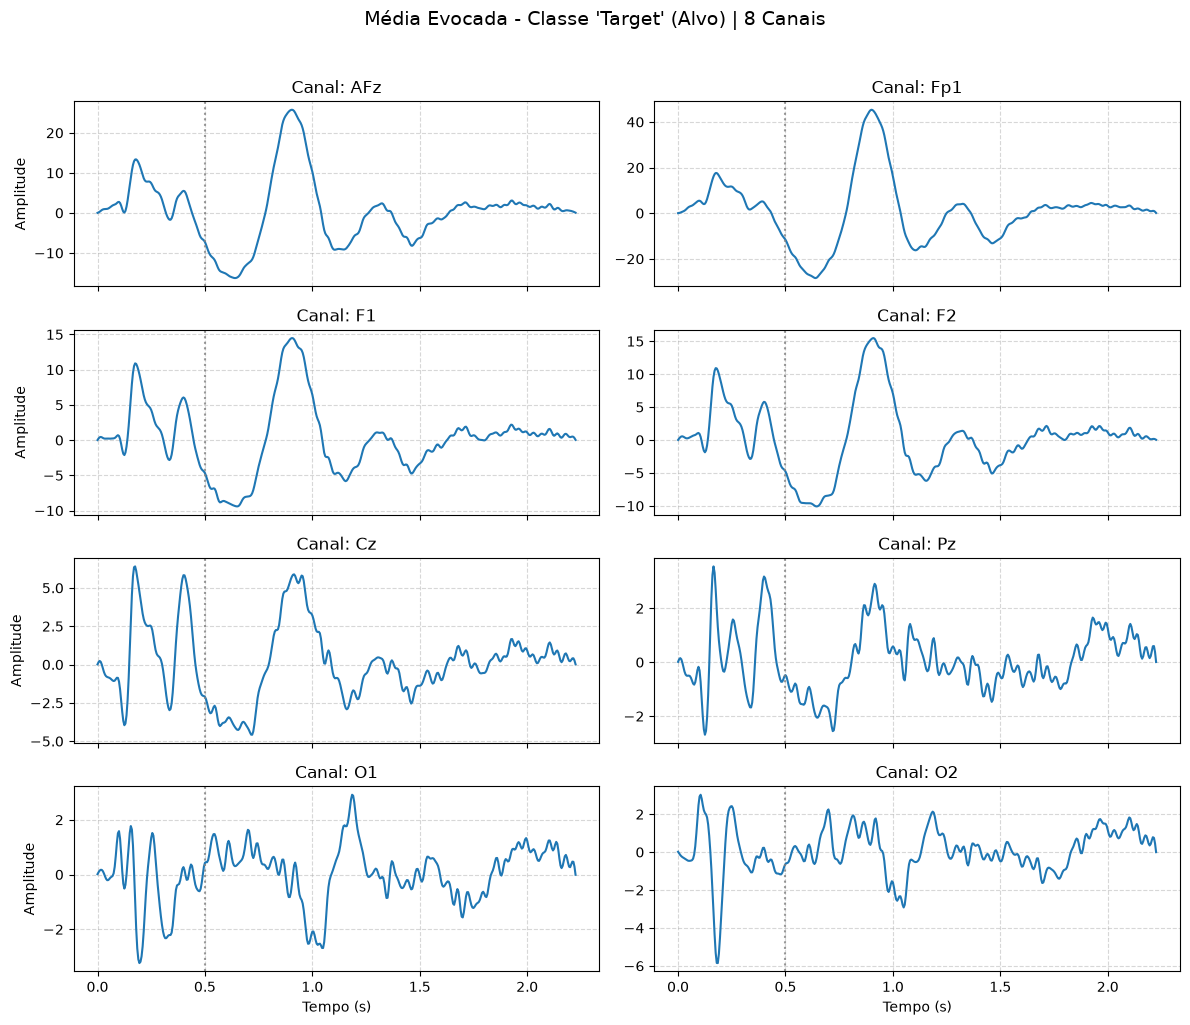

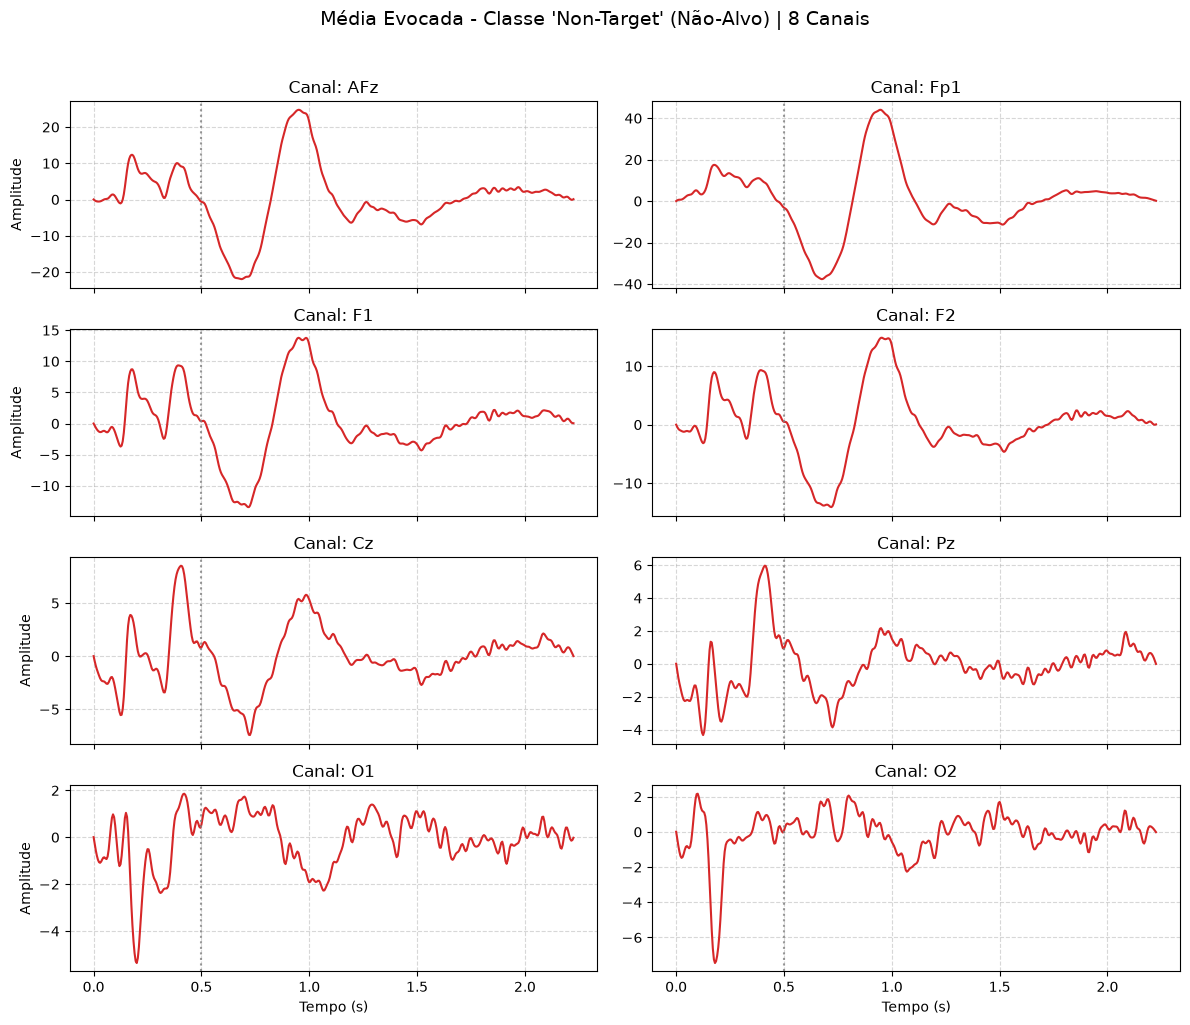

In [2]:
# Plota a média evocada para cada classe em todos os canais
def plots_evoked_classe(evoked_data, canais=None, titulo="Resposta Média Evocada", color="blue"):
    if canais is None:
        canais = ['AFz', 'Fp1', 'F1', 'F2', 'Cz', 'Pz', 'O1', 'O2']

    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 10), sharex=True)
    axes = axes.flatten()

    for i, channel_name in enumerate(canais):
        ax = axes[i]

        evoked_chan = evoked_data.copy().pick(picks=[channel_name])
        times = evoked_chan.times
        data = evoked_chan.get_data()[0]

        ax.plot(times, data, label=channel_name, color=color, linewidth=1.5)
        ax.axvline(0.5, color="gray", linestyle=":", alpha=0.8)
        ax.set_title(f"Canal: {channel_name}")
        ax.grid(True, linestyle="--", alpha=0.5)

        if i % 2 == 0:
            ax.set_ylabel("Amplitude")
        if i >= 6:
            ax.set_xlabel("Tempo (s)")

    plt.suptitle(titulo, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

# Plot da média dos eventos 'target'
plots_evoked_classe(
    evoked_target,
    canais=canais_selecionados,
    titulo="Média Evocada - Classe 'Target' (Alvo) | 8 Canais",
    color="#1f77b4"
)

# Plot da média dos eventos 'non_target'
plots_evoked_classe(
    evoked_nontarget,
    canais=canais_selecionados,
    titulo="Média Evocada - Classe 'Non-Target' (Não-Alvo) | 8 Canais",
    color="#d62728"
)

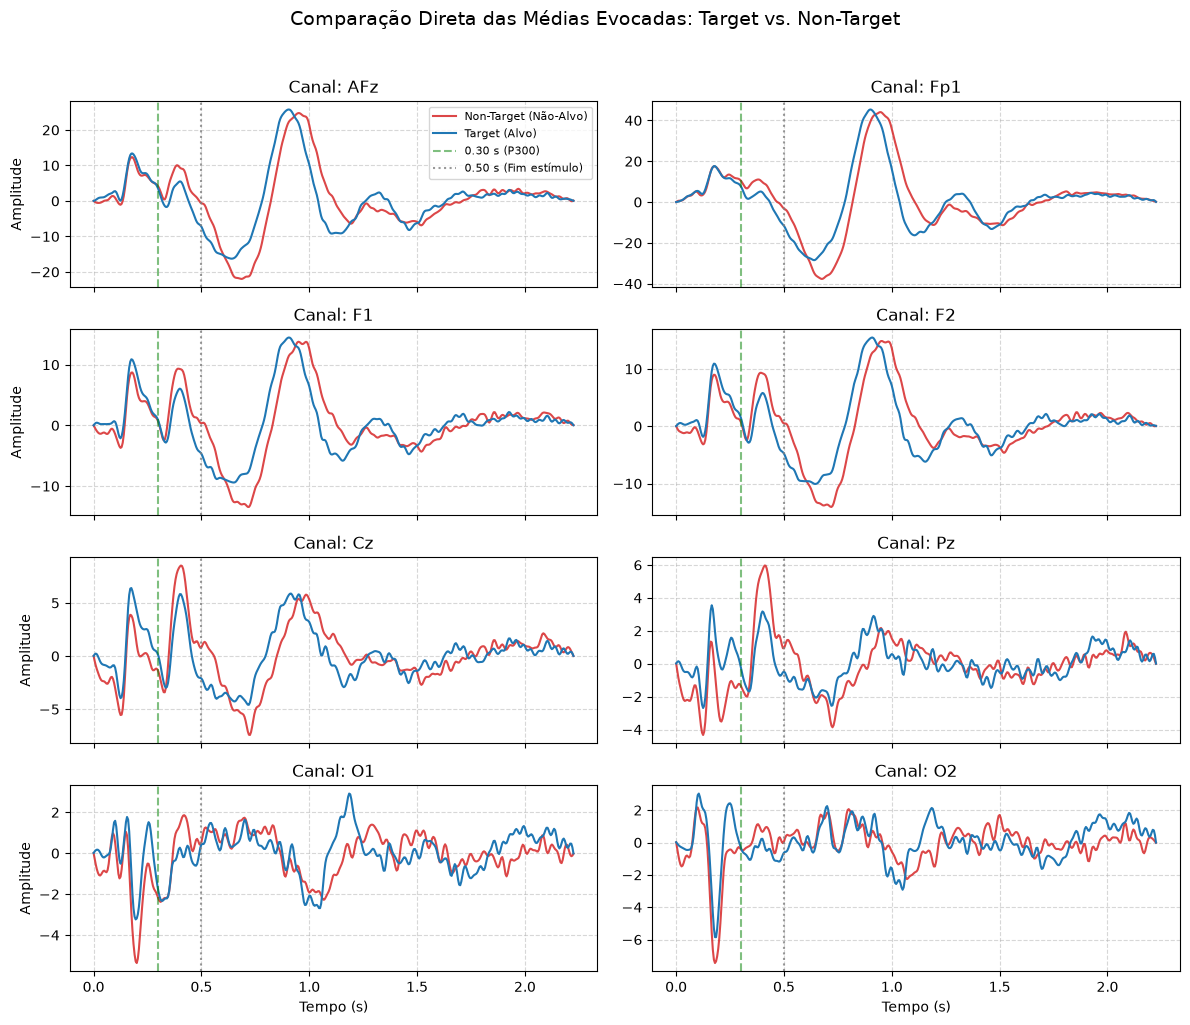

In [3]:
# Sobreposição das médias evocadas para comparação direta
def plots_comparacao_evoked(evoked_t, evoked_nt, canais=None):
    if canais is None:
        canais = ['AFz', 'Fp1', 'F1', 'F2', 'Cz', 'Pz', 'O1', 'O2']

    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 10), sharex=True)
    axes = axes.flatten()

    for i, channel_name in enumerate(canais):
        ax = axes[i]

        data_t = evoked_t.copy().pick(picks=[channel_name]).get_data()[0]
        data_nt = evoked_nt.copy().pick(picks=[channel_name]).get_data()[0]
        times = evoked_t.times

        ax.plot(times, data_nt, label="Non-Target (Não-Alvo)", color="#d62728", linewidth=1.5, alpha=0.85)
        ax.plot(times, data_t, label="Target (Alvo)", color="#1f77b4", linewidth=1.5)
        ax.axvline(0.3, color="green", linestyle="--", alpha=0.5, label="0.30 s (P300)" if i == 0 else "")
        ax.axvline(0.5, color="gray", linestyle=":", alpha=0.8, label="0.50 s (Fim estímulo)" if i == 0 else "")

        ax.set_title(f"Canal: {channel_name}")
        ax.grid(True, linestyle="--", alpha=0.5)

        if i % 2 == 0:
            ax.set_ylabel("Amplitude")
        if i >= 6:
            ax.set_xlabel("Tempo (s)")
        if i == 0:
            ax.legend(loc="upper right", fontsize=8)

    plt.suptitle("Comparação Direta das Médias Evocadas: Target vs. Non-Target", y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

plots_comparacao_evoked(evoked_target, evoked_nontarget, canais=canais_selecionados)

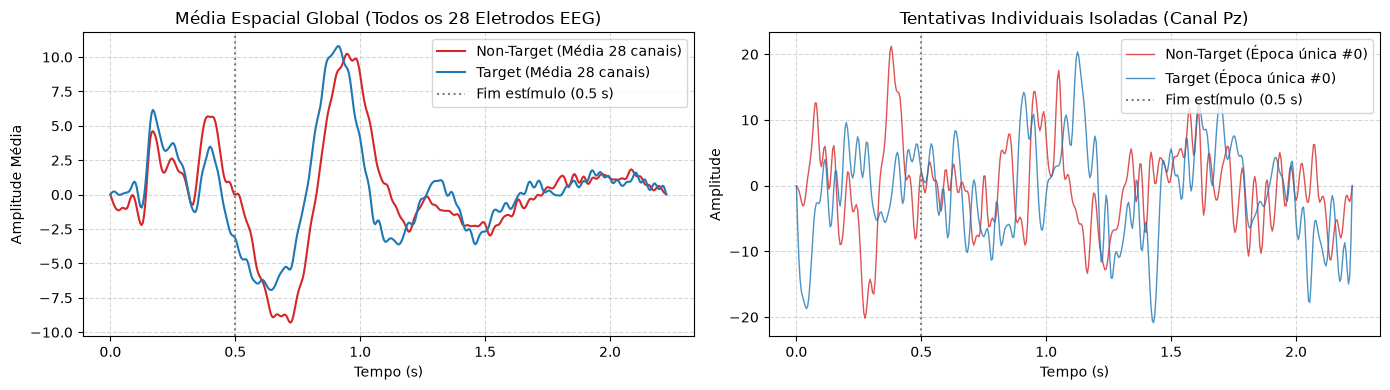

In [4]:
# Média global de todos os 28 eletrodos de EEG
media_global_t = evoked_target.copy().pick(picks='eeg').get_data().mean(axis=0)
media_global_nt = evoked_nontarget.copy().pick(picks='eeg').get_data().mean(axis=0)
times = evoked_target.times

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(times, media_global_nt, label="Non-Target (Média 28 canais)", color="#d62728", linewidth=1.5)
axes[0].plot(times, media_global_t, label="Target (Média 28 canais)", color="#1f77b4", linewidth=1.5)
axes[0].axvline(0.5, color="gray", linestyle=":", label="Fim estímulo (0.5 s)")
axes[0].set_title("Média Espacial Global (Todos os 28 Eletrodos EEG)")
axes[0].set_xlabel("Tempo (s)")
axes[0].set_ylabel("Amplitude Média")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Comparação com única amostra isolada no eletrodo Pz
unica_t = epochs["target"][0].copy().pick(picks=['Pz']).get_data()[0, 0]
unica_nt = epochs["non_target"][0].copy().pick(picks=['Pz']).get_data()[0, 0]

axes[1].plot(times, unica_nt, label="Non-Target (Época única #0)", color="#d62728", linewidth=1.0, alpha=0.8)
axes[1].plot(times, unica_t, label="Target (Época única #0)", color="#1f77b4", linewidth=1.0, alpha=0.8)
axes[1].axvline(0.5, color="gray", linestyle=":", label="Fim estímulo (0.5 s)")
axes[1].set_title("Tentativas Individuais Isoladas (Canal Pz)")
axes[1].set_xlabel("Tempo (s)")
axes[1].set_ylabel("Amplitude")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

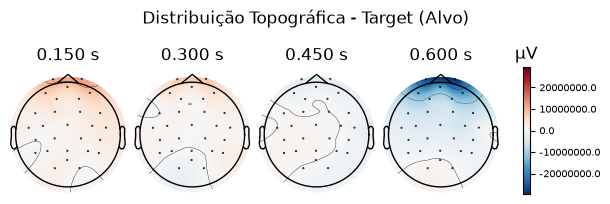

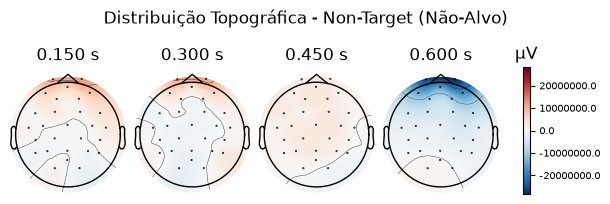

In [5]:
# Mapas topográficos do escalpo em instantes-chave após o estímulo
instantes = [0.15, 0.30, 0.45, 0.60]

fig_t = evoked_target.plot_topomap(times=instantes, ch_type='eeg', show=False)
fig_t.suptitle("Distribuição Topográfica - Target (Alvo)", y=1.05)
plt.show()

fig_nt = evoked_nontarget.plot_topomap(times=instantes, ch_type='eeg', show=False)
fig_nt.suptitle("Distribuição Topográfica - Non-Target (Não-Alvo)", y=1.05)
plt.show()